# Recipes

Pyrosm makes it possible to automate the preparation of OpenStreetMap data for your analysis with **recipes**. A recipe is a small text file that tells pyrosm which OpenStreetMap data to use and which layers to read from it, such as the street network or the buildings. A recipe can also tell pyrosm to build a graph of the street network for network analysis. When you run a recipe, pyrosm downloads the data if needed and reads the layers that you have listed. If the recipe includes a graph, pyrosm builds it too. Pyrosm then saves the layers and the graph into GeoParquet files, with the file names that you give in the recipe. GeoParquet is a compact file format for geographic data, and you can read the files with `geopandas`.

In addition, pyrosm writes a **provenance record**, which describes how pyrosm produced the files. For example, it records where the data came from and which versions of the Python packages were used.

Recipes are useful when you want to repeat your analysis later or share it with others. You keep the recipe file together with your analysis code, and anyone who runs it gets the data prepared in the same way. When you run the same recipe again, pyrosm reuses the data files that it produced earlier. If you change, for example, the settings of one layer, pyrosm reads that layer again but reuses the other files. You can run a recipe with a single command, so you can also use it as one step of a larger workflow, for example in [Snakemake](https://snakemake.readthedocs.io/).

Recipes are written in **YAML**, a plain text format that is commonly used for settings. In YAML, the indentation at the start of a line shows which settings belong together, so keep the spaces as they are when you copy an example. To read recipes, pyrosm needs the `PyYAML` library, which you can install together with pyrosm:

```bash
pip install "pyrosm[recipes]"
```

**Contents:**

- [Write and run a recipe](#write-and-run-a-recipe)
- [Run a recipe again](#run-a-recipe-again)
- [Failed and interrupted runs](#failed-and-interrupted-runs)
- [Provenance record](#provenance-record)
- [Download data for your study area](#download-data-for-your-study-area)
- [Build a street network graph](#build-a-street-network-graph)
- [Pin the data](#pin-the-data)
- [Check a recipe before running it](#check-a-recipe-before-running-it)
- [Use recipes in scripts and workflows](#use-recipes-in-scripts-and-workflows)
- [Run recipes from Python](#run-recipes-from-python)
- [All settings of a recipe](#all-settings-of-a-recipe)

## Write and run a recipe

Let's start with a recipe that reads data from the small Helsinki dataset that comes with pyrosm, so that nothing needs to be downloaded. In a notebook, we can save the recipe into a file with the `%%writefile` command. Outside a notebook, you can write the same text into a file with any text editor:

In [1]:
%%writefile helsinki_layers.yaml
recipe: pyrosm
extract:
  area:
    name: helsinki_pbf
layers:
  walking_network:
    read: network
    network_type: walking
  buildings:
    read: buildings
  food:
    read: pois
    custom_filter:
      amenity: [restaurant, cafe]
outputs:
  extract: helsinki.osm.pbf
  layers:
    walking_network: walking_network.parquet
    buildings: buildings.parquet
    food: food.parquet

Writing helsinki_layers.yaml


The recipe has four parts:

- `recipe: pyrosm` marks the file as a pyrosm recipe.
- `extract` tells which OpenStreetMap data pyrosm should use. Here, `name: helsinki_pbf` refers to the Helsinki dataset that comes with pyrosm, which you can also get with `get_data("helsinki_pbf")`.
- `layers` lists the layers that we want to read from the data, and we can name each layer as we like. The `read` key tells what kind of data the layer contains. For example, `read: network` reads the street network with `get_network()`. In the same way, `read: buildings` uses `get_buildings()`, and `read: pois` reads points of interest with `get_pois()`. The other keys of a layer are passed as parameters to the method that the `read` key selects. For example, `network_type: walking` corresponds to `get_network(network_type="walking")`. In the `food` layer, the `custom_filter` keeps only restaurants and cafes.
- `outputs` gives the names of the files that pyrosm writes: a copy of the OpenStreetMap data (`extract`) and one file for each layer.

Now we can run the recipe with the `pyrosm run` command. The `-o` option gives the folder where pyrosm saves the files. Here, we save them into a folder called `data`. The `!` at the start of the line runs the command in a terminal from the notebook:

In [2]:
!pyrosm run helsinki_layers.yaml -o data

written /tmp/data/helsinki.osm.pbf
written /tmp/data/walking_network.parquet
written /tmp/data/buildings.parquet
written /tmp/data/food.parquet
written /tmp/data/helsinki_layers.provenance.json


As we can see, pyrosm wrote five files into the `data` folder: the copy of the OpenStreetMap data, one GeoParquet file for each of the three layers, and the provenance record, which pyrosm names after the recipe. Pyrosm prints the full path of each file, and in our case, the `data` folder is inside `/tmp`. Let's read the layers with `geopandas` and plot them on a map:

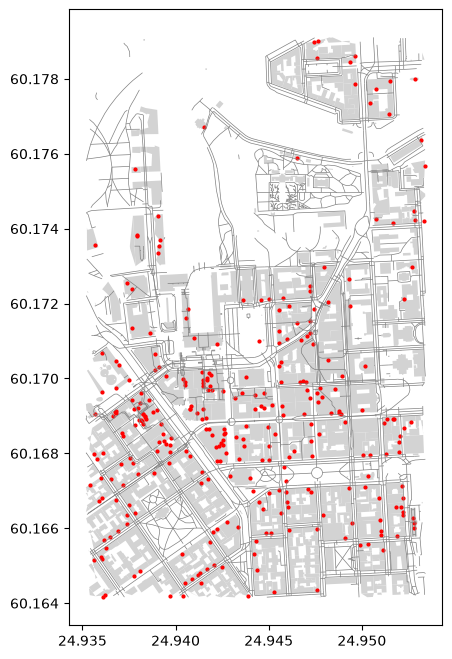

In [3]:
import geopandas as gpd

walking_network = gpd.read_parquet("data/walking_network.parquet")
buildings = gpd.read_parquet("data/buildings.parquet")
food = gpd.read_parquet("data/food.parquet")

ax = buildings.plot(figsize=(8, 8), color="lightgray")
ax = walking_network.plot(ax=ax, color="gray", linewidth=0.5)
ax = food.plot(ax=ax, color="red", markersize=4)

The map shows the buildings in light grey, the walking network as grey lines, and the restaurants and cafes in red.

## Run a recipe again

Let's see what happens when we run the same recipe again:

In [4]:
!pyrosm run helsinki_layers.yaml -o data

reused /tmp/data/helsinki.osm.pbf
reused /tmp/data/walking_network.parquet
reused /tmp/data/buildings.parquet
reused /tmp/data/food.parquet
written /tmp/data/helsinki_layers.provenance.json


This time, pyrosm reused the OpenStreetMap data and all three layers, and wrote only a new provenance record. Pyrosm runs a recipe in steps: the extract, each layer, and the graph. Before running a step, pyrosm uses the provenance record of the previous run to check whether the settings of the step, the data that the step reads, or the versions of the Python packages have changed since then. It also checks that the files that the step produced earlier are still in the `data` folder and have not been modified. If nothing has changed, pyrosm reuses the files.

Now let's change one of the layers. In the following, we add bars to the `food` layer and run the recipe again:

In [5]:
%%writefile helsinki_layers.yaml
recipe: pyrosm
extract:
  area:
    name: helsinki_pbf
layers:
  walking_network:
    read: network
    network_type: walking
  buildings:
    read: buildings
  food:
    read: pois
    custom_filter:
      amenity: [restaurant, cafe, bar]
outputs:
  extract: helsinki.osm.pbf
  layers:
    walking_network: walking_network.parquet
    buildings: buildings.parquet
    food: food.parquet

Overwriting helsinki_layers.yaml


In [6]:
!pyrosm run helsinki_layers.yaml -o data

reused /tmp/data/helsinki.osm.pbf
reused /tmp/data/walking_network.parquet
reused /tmp/data/buildings.parquet
written /tmp/data/food.parquet
written /tmp/data/helsinki_layers.provenance.json


On this run, pyrosm wrote only a new `food` layer and a new provenance record. The other files were reused, because their settings did not change.

Notice that pyrosm does not download the data again when you rerun a recipe, even if the data provider has published newer data since. If you want newer data, you can run the recipe with the `--force` option. Pyrosm then runs every step again and asks the data provider whether the data has changed since it was downloaded. Alternatively, you can add `update: true` to the `extract` part of the recipe, in which case pyrosm makes this check every time you run the recipe. The [Download responsibly](download_responsibly.ipynb#download-once-and-reuse-the-file) page explains how the check works.

## Failed and interrupted runs

Pyrosm writes the files of a run first into a temporary folder and moves them into the output folder only when every step has succeeded. If a step fails, the files and the provenance record of the previous run stay as they were.

While a recipe runs, pyrosm keeps a lock file in the output folder. The lock file prevents a second run of the same recipe from writing into the same output folder at the same time. In our example, the lock file is `data/.helsinki_layers.provenance.json.lock`. If a run is stopped abruptly, for example because the computer shuts down, the lock file stays in the folder, and you need to delete it before you can run the recipe again.

## Provenance record

The provenance record is a JSON file that describes how the files in the output folder were produced. Let's read the record of our recipe and see what information it contains:

In [7]:
import json

with open("data/helsinki_layers.provenance.json") as f:
    record = json.load(f)

list(record)

['extract',
 'inputs',
 'invocation',
 'layers',
 'outputs',
 'pyrosm_recipe_provenance',
 'recipe',
 'versions',
 'written_at']

The record contains the following information:

- `versions`: the versions of pyrosm, geopandas, shapely, pandas, numpy, pyarrow, and protobuf.
- `recipe`: the recipe, with the full path of the recipe file and of its input files. If the `extract` part has `headers`, pyrosm replaces them with `<not recorded>`, because headers can contain passwords or other credentials.
- `inputs` and `outputs`: the SHA-256 checksum of every input file (the `pbf` file, the file that defines the `area`, and the `must_cover` file) and of every file that the recipe produced, apart from the record itself. A checksum is a fingerprint of the file's content: if the content changes, the checksum changes too.
- `extract`: where the OpenStreetMap data came from, such as the data provider, the name of the extract, its web address, the time of its snapshot, and the extracts that were merged into it.
- `layers`: the number of features in each layer. If the recipe builds a graph, the record also has a `graph` key with the number of nodes and edges. Our Helsinki recipe builds no graph, so its record has no `graph` key.
- `invocation` and `written_at`: how the run was started, and when it finished.
- `pyrosm_recipe_provenance`: the version of the record's format.

For example, the versions of the Python packages look like this:

In [8]:
record["versions"]

{'geopandas': '1.1.3',
 'numpy': '2.4.6',
 'pandas': '3.0.3',
 'protobuf': '6.33.5',
 'pyarrow': '24.0.0',
 'pyrosm': '0.27.0',
 'shapely': '2.1.2'}

## Download data for your study area

In the previous examples, the data came from the Helsinki dataset that comes with pyrosm. In your own work, you typically need to download the OpenStreetMap data for your study area first. Let's write a recipe that downloads the data for a small area in Monaco and reads the buildings from it:

In [9]:
%%writefile monaco.yaml
recipe: pyrosm
extract:
  area:
    bbox: [7.418, 43.728, 7.428, 43.738]
  directory: osm_data
layers:
  buildings:
    read: buildings
outputs:
  extract: monaco.osm.pbf
  layers:
    buildings: monaco_buildings.parquet

Writing monaco.yaml


Here, the `area` is a bounding box `[minx, miny, maxx, maxy]` in longitude and latitude. Pyrosm passes the area to `get_data_by_area()`, which downloads the smallest extract that contains the area and crops the data to the bounding box. The `directory` key gives the folder where pyrosm keeps the downloaded extract, so that it can reuse the file later instead of downloading it again. Notice that this folder needs to be separate from the output folder: neither of them can be inside the other. Let's run the recipe:

In [10]:
!pyrosm run monaco.yaml -o data

Finding the extracts took 00:07
written /tmp/data/monaco.osm.pbf
written /tmp/data/monaco_buildings.parquet
written /tmp/data/monaco.provenance.json


Pyrosm first searched for the extracts that contain our area and then downloaded one of them. It wrote the cropped data into `monaco.osm.pbf` and the buildings into `monaco_buildings.parquet`. The downloaded extract itself stays in the `osm_data` folder. The provenance record tells which extract pyrosm downloaded:

In [11]:
with open("data/monaco.provenance.json") as f:
    record = json.load(f)

{key: record["extract"][key] for key in ["provider", "extract", "url", "snapshot"]}

{'provider': 'Movisda',
 'extract': 'MC',
 'url': 'https://osm.download.movisda.io/admin/MC-latest.osm.pbf',
 'snapshot': '2026-10-30T01:00:00+00:00'}

The record shows that pyrosm downloaded Movisda's extract of Monaco (`MC`), which is the smallest extract that contains our area. The `snapshot` tells when Movisda took the data from OpenStreetMap. In our case, this was on 28 October 2026.

Besides a bounding box, you can give the area in three other ways:

- `place: "Kallio, Helsinki"` is a place name, which pyrosm turns into an area with `pyrosm.geocode()`. Notice that this sends a request to the public Nominatim geocoding service (see [Download responsibly](download_responsibly.ipynb#geocode-sparingly)).
- `file: study_area.gpkg` is a GeoPackage, GeoJSON, or GeoParquet file whose geometries make up the area. You can choose one layer of a GeoPackage with `layer: <name of the layer>`.
- `name: helsinki_pbf` is the name of a dataset that `get_data()` knows, as in our first recipe.

If you give a relative path for an input file, pyrosm looks for the file relative to the folder of the recipe.

When you give the area as a bounding box, a place name, or a file, the other keys of `extract` are parameters of `get_data_by_area()`. When you give it with `name`, they are parameters of `get_data()`. With these keys, you can choose how pyrosm selects and crops the extract, for example:

- With `strategy: smallest_total`, pyrosm also considers sets of smaller extracts that together cover the area. Pyrosm downloads such a set and merges the extracts into one file if their files are smaller in total than the smallest single extract that contains the area. It also chooses the set if the size of the single extract is unknown.
- With `crop: polygon`, pyrosm crops the data to the shape of the area instead of its bounding box.
- With `must_cover: {file: stops.gpkg}`, the extract only needs to contain the places in the given file, such as transit stops.

The [Downloading OSM data](downloading_data.ipynb#download-the-smallest-extract-that-contains-an-area) page explains these parameters in more detail.

## Build a street network graph

A recipe can also build a graph of the street network, which you can use for network analysis, for example to find shortest paths (see [Working with graphs](graphs.ipynb)). Let's add a walking graph to our Monaco recipe:

In [12]:
%%writefile monaco.yaml
recipe: pyrosm
extract:
  area:
    bbox: [7.418, 43.728, 7.428, 43.738]
  directory: osm_data
layers:
  buildings:
    read: buildings
graph:
  network:
    network_type: walking
outputs:
  extract: monaco.osm.pbf
  layers:
    buildings: monaco_buildings.parquet
  graph:
    nodes: monaco_walking_nodes.parquet
    edges: monaco_walking_edges.parquet

Overwriting monaco.yaml


The `network` key of `graph` holds the parameters of `get_network()`. In our recipe, it sets the type of the network to `walking`. The `outputs` part names two files for the graph: one for its nodes and one for its edges. Let's run the recipe:

In [13]:
!pyrosm run monaco.yaml -o data

reused /tmp/data/monaco.osm.pbf
reused /tmp/data/monaco_buildings.parquet
written /tmp/data/monaco_walking_nodes.parquet
written /tmp/data/monaco_walking_edges.parquet
written /tmp/data/monaco.provenance.json


Pyrosm reused the data and the buildings. It wrote new files for the nodes and the edges of the graph, and a new provenance record. Let's plot the graph:

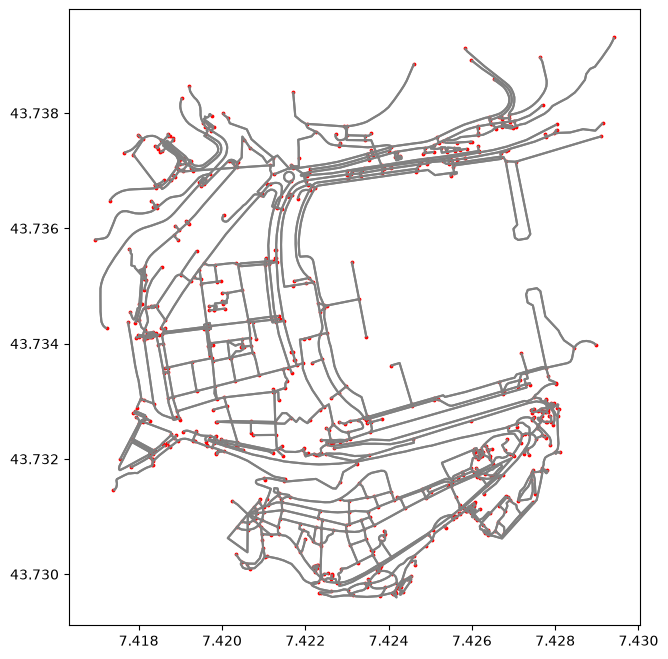

In [14]:
nodes = gpd.read_parquet("data/monaco_walking_nodes.parquet")
edges = gpd.read_parquet("data/monaco_walking_edges.parquet")

ax = edges.plot(figsize=(8, 8), color="gray")
ax = nodes.plot(ax=ax, color="red", markersize=3)
ax.ticklabel_format(useOffset=False)

The map shows the nodes of the walking graph as red points and the edges that connect them as grey lines. By default, pyrosm simplifies the graph. It removes the nodes that are needed only to draw the bends of a street between two intersections, and joins the edges on both sides of each removed node into one edge. However, pyrosm does not join edges where the speed limit or the type of the road changes (see [Simplify the graph](graphs.ipynb#simplify-the-graph)). After pyrosm has merged edges in this way, columns such as the OpenStreetMap id or the street name can hold the values of all the original edges. Pyrosm saves such values as text in JSON format, and you can turn the text back into Python lists with `json.loads()`.

In addition, pyrosm keeps only the largest connected part of the network, which means that it removes small groups of streets that are not connected to the rest of the network. The other keys of `graph` control how pyrosm builds the graph, and pyrosm passes them to `pyrosm.graphs.graph_tables()`. For example, `simplify: false` keeps the nodes that the simplification would remove, and `retain_all: true` also keeps the parts of the network that are not connected to the largest one.

The type of the network determines the direction of the edges. In a walking graph, every edge runs in both directions, while a driving graph keeps one-way streets one-way. With `force_bidirectional: true`, every edge runs in both directions.

## Pin the data

When pyrosm downloads the data for a recipe, it gets the version that the provider offers at that moment. If someone runs your recipe a year later on their own computer, they most likely get newer data. Pyrosm cannot download an older version of the data. However, you can tell pyrosm which data you expect, and pyrosm stops with an error if the data is different. This is called **pinning** the data, and you can do it in the `extract` part of the recipe with two keys:

- `snapshot: 2026-10-28` requires that the provider took the data from OpenStreetMap on that day (in UTC). If you give both a date and a time, the snapshot needs to have exactly that date and time.
- `sha256: "<checksum>"` requires that the data has the given SHA-256 checksum. Put the checksum in quotes, so that YAML reads it as text.

You can find both values in the provenance record of an earlier run. You can also pin an input file by adding `sha256` next to its `file` key, for example `pbf: {file: helsinki.osm.pbf, sha256: "<checksum>"}`. This works for the `pbf` file, the file that defines the `area`, and the `must_cover` file.

Let's see what happens when the data does not match the pin. In the following, we pin our Monaco recipe to 1 January 2026:

In [15]:
%%writefile monaco.yaml
recipe: pyrosm
extract:
  area:
    bbox: [7.418, 43.728, 7.428, 43.738]
  directory: osm_data
  snapshot: 2026-01-01
layers:
  buildings:
    read: buildings
graph:
  network:
    network_type: walking
outputs:
  extract: monaco.osm.pbf
  layers:
    buildings: monaco_buildings.parquet
  graph:
    nodes: monaco_walking_nodes.parquet
    edges: monaco_walking_edges.parquet

Overwriting monaco.yaml


In [16]:
!pyrosm run monaco.yaml -o data

pyrosm: extract.snapshot: the extract's snapshot is 2026-10-30T01:00:00+00:00, not the pinned 2026-01-01


Pyrosm stopped with an error, because the snapshot of the data is not from the day that we pinned. The files and the provenance record of the previous run stay as they were.

## Check a recipe before running it

The `pyrosm validate` command checks a recipe without running it. For example, it reports unknown keys, input files that do not exist, and output file names that are not valid. In the following, we have misspelt `network_type` in a recipe:

In [17]:
%%writefile misspelt.yaml
recipe: pyrosm
extract:
  area:
    name: helsinki_pbf
layers:
  walking_network:
    read: network
    network_typ: walking
outputs:
  extract: helsinki.osm.pbf
  layers:
    walking_network: walking_network.parquet

Writing misspelt.yaml


In [18]:
!pyrosm validate misspelt.yaml

pyrosm: layers.walking_network: unknown keyword 'network_typ' (one of custom_filter, extra_attributes, filter_type, network_type, read, tags_to_keep, timestamp)


The error message names the misspelt key and lists the keys that pyrosm accepts in its place. Pyrosm makes the same checks at the start of a run, before it downloads or reads anything. These checks cover the names of all keys and some of the values, such as the bounding box and the names of the output files. Pyrosm checks the other values when it calls the functions that use them. For example, it checks the `network_type` when it reads the network.

## Use recipes in scripts and workflows

When `pyrosm run` or `pyrosm validate` finishes, it returns an **exit status**, a number that scripts and workflow tools can check. A status of 0 means that the command succeeded. A status of 1 means that pyrosm stopped because of a problem, for example with the recipe, its data, or a download. A status of 2 means that the command itself has an error, such as an unknown option. The commands never stop to ask for input. This means that you can use them in shell scripts and in workflow tools, such as Snakemake. In a Snakemake rule, you list all the files that the recipe produces, and `pyrosm run` writes them:

```python
rule osm_layers:
    input:
        "recipes/helsinki_layers.yaml",
    output:
        "data/helsinki.osm.pbf",
        "data/walking_network.parquet",
        "data/buildings.parquet",
        "data/food.parquet",
        "data/helsinki_layers.provenance.json",
    shell:
        "pyrosm run {input} -o data"
```

The other commands of pyrosm are described on the [Command line](command_line.ipynb) page.

## Run recipes from Python

You can also check and run recipes in Python with the `pyrosm.recipes` module. The `validate()` function checks a recipe without running it, and `run()` runs it and returns the paths of the files, with the provenance record last:

In [19]:
from pyrosm import recipes

recipes.validate("helsinki_layers.yaml")
paths = recipes.run("helsinki_layers.yaml", out_dir="data")
paths

[PosixPath('/tmp/data/helsinki.osm.pbf'),
 PosixPath('/tmp/data/walking_network.parquet'),
 PosixPath('/tmp/data/buildings.parquet'),
 PosixPath('/tmp/data/food.parquet'),
 PosixPath('/tmp/data/helsinki_layers.provenance.json')]

Notice that `run()` returns only the paths. Unlike the command line, it does not tell which files were written and which were reused. The `force=True` parameter of `run()` does the same as the `--force` option of `pyrosm run`.

A recipe does not need to be a file. In Python, you can also give the recipe as a dictionary that has the same parts as a recipe file. Your own code can then build the recipe, for example from the settings of a larger analysis, and you do not need to write a recipe file at all. Relative paths in the dictionary start from the folder that you give with the `base_dir` parameter. This applies, for example, to the `pbf` file below. Pyrosm also saves the output files into that folder, unless you give `out_dir`. Without `base_dir`, relative paths start from the current folder. Because a dictionary has no file name, pyrosm cannot name the provenance record after it, so you need to give the name of the record with the `provenance` key in the `outputs` part.

In the following, we read the cafes from the copy of the Helsinki data that our first recipe saved into the `data` folder:

In [20]:
recipe = {
    "recipe": "pyrosm",
    "pbf": {"file": "helsinki.osm.pbf"},
    "layers": {"cafes": {"read": "pois", "custom_filter": {"amenity": ["cafe"]}}},
    "outputs": {
        "layers": {"cafes": "cafes.parquet"},
        "provenance": "cafes.provenance.json",
    },
}
recipes.run(recipe, base_dir="data")

[PosixPath('/tmp/data/cafes.parquet'),
 PosixPath('/tmp/data/cafes.provenance.json')]

Pyrosm found `helsinki.osm.pbf` in the `data` folder and saved the cafes and the provenance record into the same folder. You can also use `base_dir` when the recipe is a file. Pyrosm then looks for the input files of the recipe in that folder and saves the output files there, instead of using the folder that contains the recipe file.

A recipe file can also be written in JSON instead of YAML, and pyrosm runs it in the same way. If your recipe is JSON text in Python, first turn it into a dictionary with `json.loads()`. The `validate()` and `run()` functions treat every string as the name of a recipe file.

## All settings of a recipe

A recipe can have the following parts:

| Part | What it contains |
|---|---|
| `recipe` | Always `pyrosm`. Required. |
| `version` | The version of the recipe format. Only version `1` exists, and it is the default. |
| `extract` | The OpenStreetMap data to download, described in [Download data for your study area](#download-data-for-your-study-area). |
| `pbf` | An OpenStreetMap file that you already have, as `pbf: {file: <path>}`. Use it instead of `extract`. |
| `reader` | Parameters for `pyrosm.OSM`, such as `bounding_box` or `keep_metadata`. Pyrosm uses them when it reads the data for the layers and the graph. A recipe can have `reader` only if it has layers or a graph. |
| `layers` | The layers to read. |
| `graph` | The graph to build. |
| `outputs` | The names of the files that pyrosm writes. Required. |

A recipe needs at least one of `extract`, `layers`, and `graph`. Pyrosm reads the layers and the graph either from the data of the `extract` part or from the `pbf` file. A recipe with layers or a graph therefore needs either `extract` or `pbf`, but not both.

In the `extract` part, the `area` key is required, and the `snapshot` and `sha256` keys pin the data (see [Pin the data](#pin-the-data)). The other keys are parameters of `get_data_by_area()` or `get_data()`, except `output_path`, which pyrosm sets itself, and `opener`, which a recipe cannot give. If `directory` is a relative path, it is relative to the folder that contains the recipe file, or to the `base_dir` folder if you give `base_dir` (see [Run recipes from Python](#run-recipes-from-python)).

In the `layers` part, each layer needs the `read` key. Its value selects the method of `pyrosm.OSM` that reads the layer:

| `read` | Method |
|---|---|
| `network` | `get_network()` |
| `buildings` | `get_buildings()` |
| `pois` | `get_pois()` |
| `landuse` | `get_landuse()` |
| `natural` | `get_natural()` |
| `boundaries` | `get_boundaries()` |
| `custom` | `get_data_by_custom_criteria()` |

The other keys of a layer are parameters of that method. The only exception is the `nodes` parameter of `get_network()`, which a recipe does not accept. If you need the nodes of a network, build a graph instead. If the method finds no data, pyrosm writes an empty layer.

In the `graph` part, `network` holds the parameters of `get_network()`, apart from `nodes`. The other keys are parameters of `pyrosm.graphs.graph_tables()`, apart from `nodes`, `edges`, and `network_type`, which pyrosm sets itself. The type of the network goes under `network`.

If a recipe has an `extract` part, its `outputs` part needs an `extract` key, which names the file of the OpenStreetMap data. A recipe that reads a `pbf` file cannot have this key. In the `outputs` part, `layers` names a file for each layer, and `graph` names the `nodes` and `edges` files. With `provenance`, you can choose the name of the provenance record. By default, the record is named after the recipe, as `<name of the recipe>.provenance.json`. All names are relative to the output folder, which is the folder that you give with `-o` or, by default, the folder of the recipe. The name of the OpenStreetMap data file needs to end with `.pbf`. The names of the layer and graph files need to end with `.parquet`, and the name of the provenance record with `.json`. The names also need to be valid file names on Windows, even if you work on Linux or macOS.

You can find more example recipes in the [examples/recipes](https://github.com/pyrosm/pyrosm/tree/main/examples/recipes) folder of the pyrosm repository.